# **Decision Trees and Cross Validation**

## Introduction

https://archive.ics.uci.edu/dataset/579/myocardial+infarction+complications


## Exploratory Data Analysis (EDA)

Missing values in this data 

In [3]:
#Importing the relevant libraries 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#Importing the cross validation data split 
df_train = pd.read_csv("training_data.csv")
df_validate = pd.read_csv("validation_data.csv")
df_test = pd.read_csv("test_data.csv")

#Data set of merged training and validation for EDA purposes
#df_full = pd.concat([df_train, df_validate], ignore_index=True)
#df_full

df_train

,AGE,SEX,INF_ANAM,STENOK_AN,FK_STENOK,IBS_POST,GB,SIM_GIPERT,DLIT_AG,ZSN_A,...,NOT_NA_2_n,NOT_NA_3_n,LID_S_n,B_BLOK_S_n,ANT_CA_S_n,GEPAR_S_n,ASP_S_n,TIKL_S_n,TRENT_S_n,mortality
0,75.0,0,1.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,...,0.0,NaN,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1
1,62.0,0,1.0,4.0,2.0,1.0,3.0,0.0,5.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0
2,52.0,0,0.0,0.0,0.0,0.0,3.0,0.0,6.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0
3,88.0,0,2.0,6.0,2.0,2.0,NaN,NaN,NaN,NaN,...,1.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,1
4,68.0,1,0.0,6.0,2.0,1.0,2.0,0.0,7.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1015,73.0,1,1.0,4.0,2.0,2.0,2.0,0.0,NaN,0.0,...,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0
1016,63.0,1,1.0,6.0,2.0,1.0,3.0,0.0,7.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0
1017,75.0,0,0.0,0.0,0.0,2.0,2.0,0.0,2.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0
1018,65.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0


Explanation

In [5]:
df_train[df_train['AGE'].isnull()]

,AGE,SEX,INF_ANAM,STENOK_AN,FK_STENOK,IBS_POST,GB,SIM_GIPERT,DLIT_AG,ZSN_A,...,NOT_NA_2_n,NOT_NA_3_n,LID_S_n,B_BLOK_S_n,ANT_CA_S_n,GEPAR_S_n,ASP_S_n,TIKL_S_n,TRENT_S_n,mortality
240,NaN,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0
850,NaN,0,0.0,6.0,2.0,1.0,2.0,0.0,7.0,0.0,...,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0
918,NaN,1,1.0,3.0,2.0,1.0,2.0,0.0,5.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0
926,NaN,1,0.0,3.0,2.0,2.0,2.0,0.0,7.0,1.0,...,1.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0


In [6]:
#Assessing if there are any null values and the size of the data set
df_train.isnull().sum()



AGE           4
SEX           0
INF_ANAM      3
STENOK_AN    65
FK_STENOK    43
             ..
GEPAR_S_n     7
ASP_S_n       7
TIKL_S_n      8
TRENT_S_n     8
mortality     0
Length: 108, dtype: int64

In [7]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Columns: 108 entries, AGE to mortality
dtypes: float64(106), int64(2)
memory usage: 860.8 KB


 Explanation need some sort of imputation. Website where code is from says no missing values for age so explore this. 

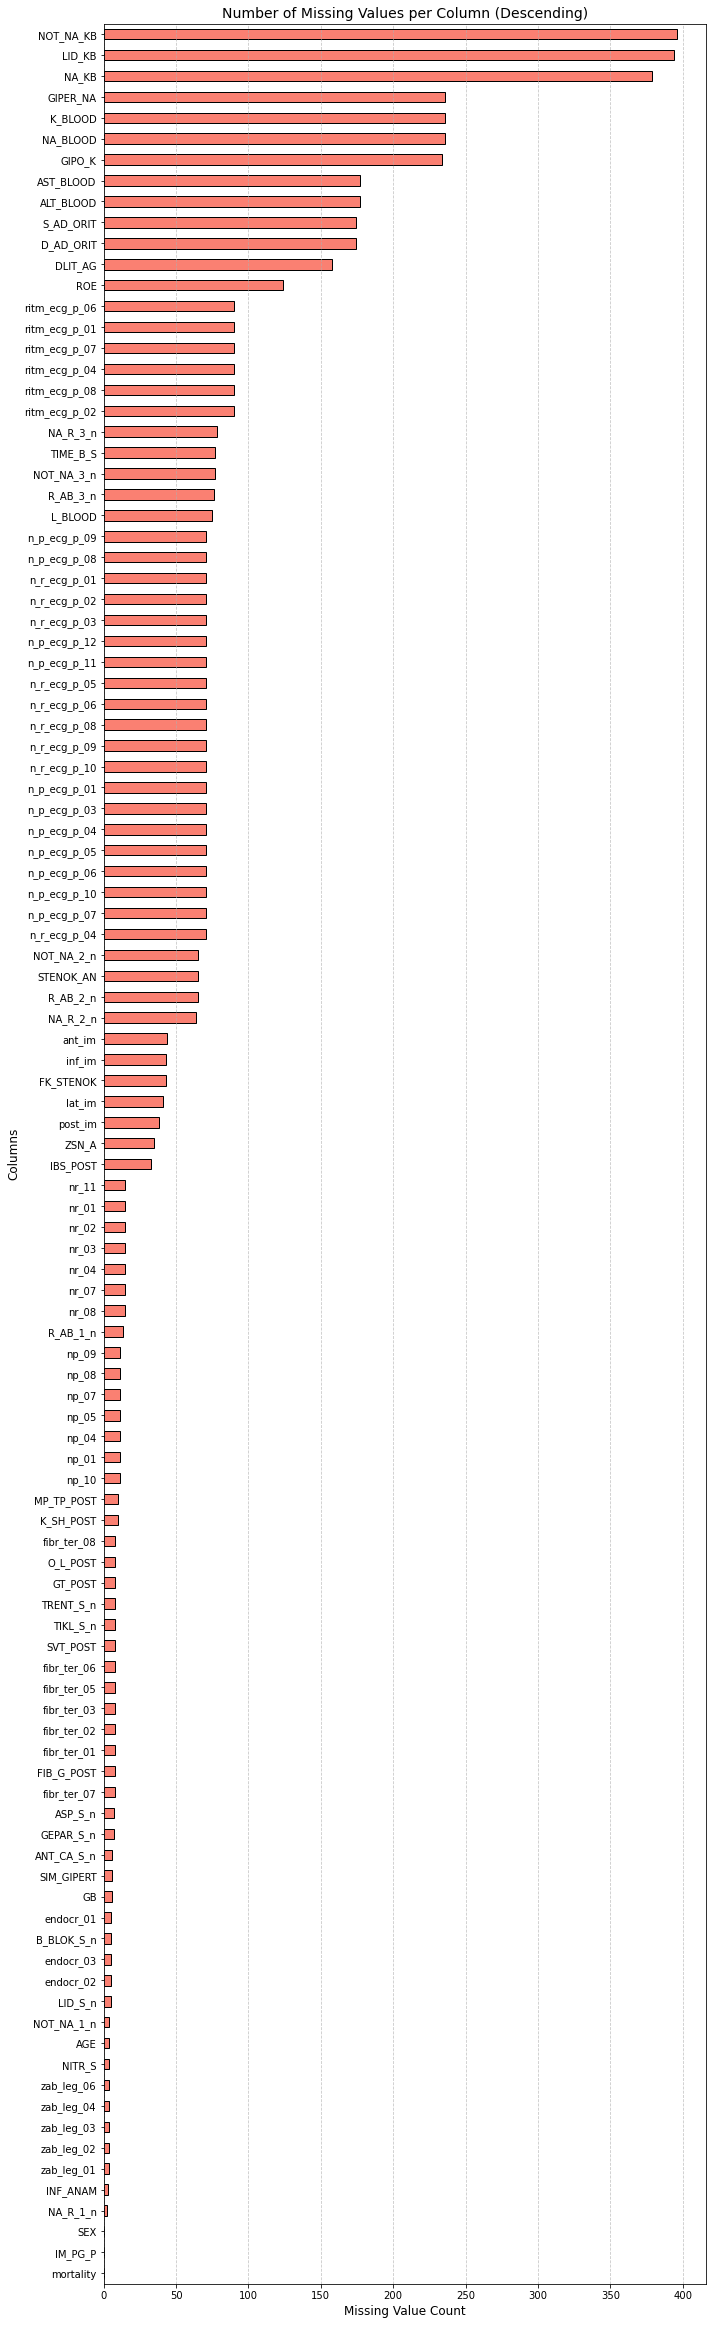

In [8]:
#PLOT OF MISSING VALUES

# 1. Calculate missing values and sort them in descending order
missing_values = df_train.isnull().sum().sort_values(ascending=False)

# Optional: Uncomment the line below if you only want to show columns that actually have missing values (> 0)
# missing_values = missing_values[missing_values > 0]

# 2. Create a horizontal bar plot and adjust figure height for readability
plt.figure(figsize=(10, max(6, len(missing_values) * 0.3))) # Dynamically scales height based on column count
missing_values.plot(kind='barh', color='salmon', edgecolor='black')

# 3. Customize the graph labels and layout
plt.title('Number of Missing Values per Column (Descending)', fontsize=14)
plt.xlabel('Missing Value Count', fontsize=12)
plt.ylabel('Columns', fontsize=12)
plt.gca().invert_yaxis()  # Puts the column with the highest missing values at the very top
plt.grid(axis='x', linestyle='--', alpha=0.7)

# 4. Display the plot
plt.tight_layout()
plt.show()

In [9]:
# Identify the top 3 columns with the most missing values
top_3_missing = df_train.isnull().sum().nlargest(3).index

print("Columns being dropped:")
print(top_3_missing)

# Drop these columns from both datasets
df_train = df_train.drop(columns=top_3_missing)
df_validate = df_validate.drop(columns=top_3_missing)

# Remove observations with missing AGE
df_train = df_train.dropna(subset=['AGE']).copy()
df_validate = df_validate.dropna(subset=['AGE']).copy()

# Check dimensions
print("Training:", df_train.shape)
print("Validation:", df_validate.shape)

Columns being dropped:
Index(['NOT_NA_KB', 'LID_KB', 'NA_KB'], dtype='object')
Training: (1016, 105)
Validation: (337, 105)


In [11]:
# Continuous numerical variables
numerical_cols = [
    'S_AD_ORIT',
    'D_AD_ORIT',
    'K_BLOOD',
    'NA_BLOOD',
    'ALT_BLOOD',
    'AST_BLOOD',
    'L_BLOOD',
    'ROE'
]

# Categorical variables
categorical_cols = [
    col for col in df_train.columns
    if col not in numerical_cols + ['AGE', 'mortality']
]

from sklearn.impute import SimpleImputer

# Initialise imputers
median_imputer = SimpleImputer(strategy='median')
mode_imputer = SimpleImputer(strategy='most_frequent')

# Median imputation for numerical variables
df_train[numerical_cols] = median_imputer.fit_transform(
    df_train[numerical_cols]
)

# Mode imputation for categorical variables
df_train[categorical_cols] = mode_imputer.fit_transform(
    df_train[categorical_cols]
)

# Check remaining missing values
print(df_train.isnull().sum().sum())


0


In [12]:
# Median imputation for validation data
df_validate[numerical_cols] = median_imputer.transform(
    df_validate[numerical_cols]
)

# Mode imputation for validation data
df_validate[categorical_cols] = mode_imputer.transform(
    df_validate[categorical_cols]
)

# Check remaining missing values
print(df_validate.isnull().sum().sum())

0


In [13]:
# Check remaining missing values
print("Training missing values:")
print(df_train.isnull().sum().sum())

print("Validation missing values:")
print(df_validate.isnull().sum().sum())

# Check dataset dimensions
print("Training shape:", df_train.shape)
print("Validation shape:", df_validate.shape)

Training missing values:
0
Validation missing values:
0
Training shape: (1016, 105)
Validation shape: (337, 105)


In [14]:
print(df_train['mortality'].isnull().sum())
print(df_validate['mortality'].isnull().sum())

0
0


Talk about the imputation. Drop null values for age. Drop top 3 worst columns


## Decision trees

A decision tree is a machine learning algorithm that can be used for classification. In this analysis....



To assess the quality of each model, 1-fold cross-validation is used  The model is trained using four folds and evaluated using the remaining fold. This process is repeated five times so that each fold is used as the validation set once.

The five accuracy values outputted in each section therefore represent the model's performance on five different subsets of the data. The mean accuracy provides an overall measure of predictive performance, while the standard deviation indicates how much the model's performance varies between folds.

The code used in this section is taken from the websites linked below. Variables have been altered to match this data set. 
https://www.datacamp.com/tutorial/decision-tree-classification-python
https://scikit-learn.org/stable/modules/cross_validation.html


### Decision tree 


In [15]:
# Load sklearn libraries
from sklearn.tree import DecisionTreeClassifier 
from sklearn.model_selection import cross_val_score

In [16]:
# Training data
X_train = df_train.drop(columns=['mortality'])
y_train = df_train['mortality']

# Validation data
X_validate = df_validate.drop(columns=['mortality'])
y_validate = df_validate['mortality']

# Check dimensions
print("Training predictors:", X_train.shape)
print("Validation predictors:", X_validate.shape)


# Initialise decision tree classifier - using Gini Impurity 
dt = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

# Train the model
dt.fit(X_train, y_train)

Training predictors: (1016, 104)
Validation predictors: (337, 104)


DecisionTreeClassifier(random_state=42)

In [17]:
# Predict mortality
y_pred = dt.predict(X_validate)

# Display first 10 predictions
print(y_pred[:10])

# Compare actual and predicted outcomes
results = pd.DataFrame({
    'Actual': y_validate,
    'Predicted': y_pred
})

print(results.head(10))

[0 0 0 0 1 0 0 0 0 0]
   Actual  Predicted
0       0          0
1       0          0
2       1          0
3       0          0
4       0          1
5       0          0
6       0          0
7       0          0
8       0          0
9       0          0


In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Calculate performance metrics
accuracy = accuracy_score(y_validate, y_pred)
precision = precision_score(y_validate, y_pred, zero_division=0)
recall = recall_score(y_validate, y_pred, zero_division=0)
f1 = f1_score(y_validate, y_pred, zero_division=0)

# Display results
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

# Full classification report
print(classification_report(y_validate, y_pred, zero_division=0))

Accuracy: 0.8189910979228486
Precision: 0.43137254901960786
Recall: 0.4074074074074074
F1-score: 0.419047619047619
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       283
           1       0.43      0.41      0.42        54

    accuracy                           0.82       337
   macro avg       0.66      0.65      0.66       337
weighted avg       0.81      0.82      0.82       337



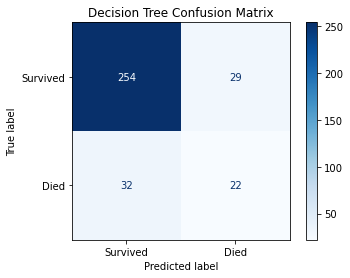

In [19]:
# Calculate confusion matrix
cm = confusion_matrix(y_validate, y_pred, labels=[0, 1])

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Survived', 'Died']
)

disp.plot(cmap='Blues')
plt.title('Decision Tree Confusion Matrix')
plt.show()

The decision tree correctly classifies approximately ...

## Visualising the decision trees


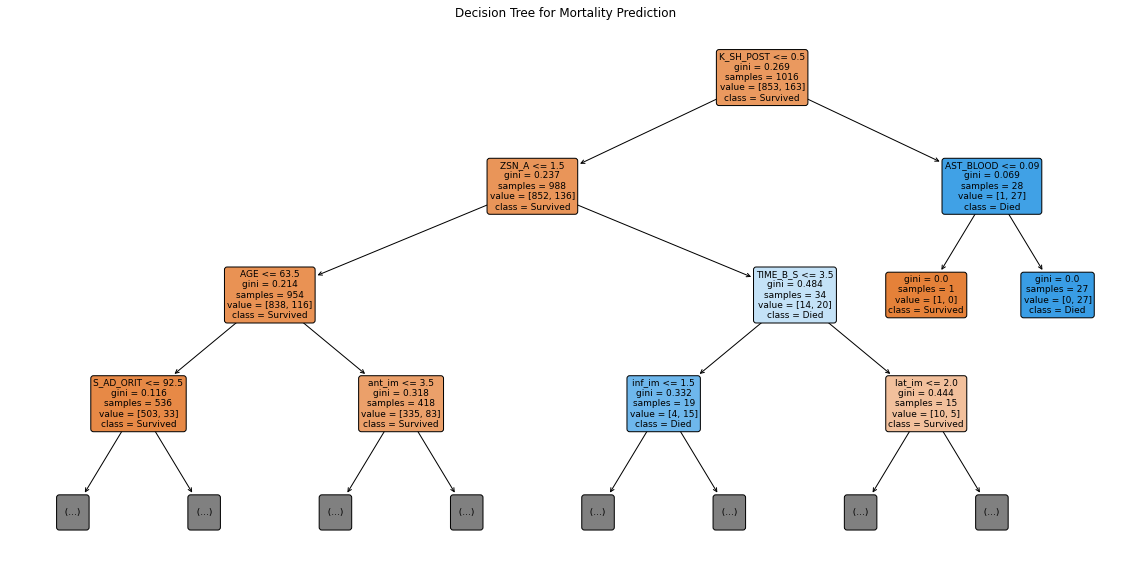

In [20]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    dt,
    feature_names=X_train.columns,
    class_names=['Survived', 'Died'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title('Decision Tree for Mortality Prediction')
plt.show()

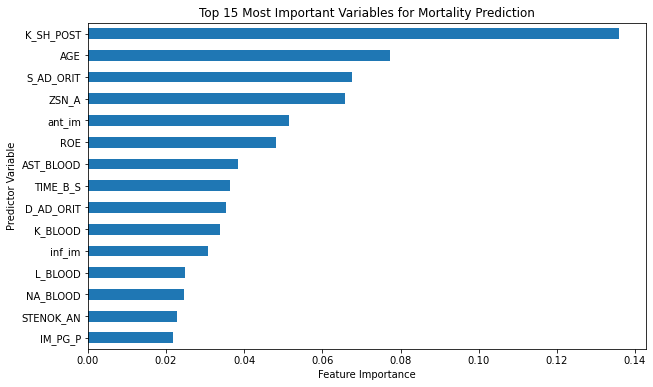

In [21]:
# Extract feature importance
importance = pd.Series(
    dt.feature_importances_,
    index=X_train.columns
)

# Sort by importance
importance = importance.sort_values(ascending=False)

# Plot top 15 features
plt.figure(figsize=(10, 6))

importance.head(15).sort_values().plot(kind='barh')

plt.xlabel('Feature Importance')
plt.ylabel('Predictor Variable')
plt.title('Top 15 Most Important Variables for Mortality Prediction')

plt.show()

In [22]:
# Predictions on training data
y_train_pred = dt.predict(X_train)

# Calculate accuracy
train_accuracy = accuracy_score(y_train, y_train_pred)
validate_accuracy = accuracy_score(y_validate, y_pred)

print("Training Accuracy:", train_accuracy)
print("Validation Accuracy:", validate_accuracy)

Training Accuracy: 1.0
Validation Accuracy: 0.8189910979228486


In [23]:
# Create decision tree with maximum depth of 5
dt_depth5 = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    random_state=42
)

# Train model
dt_depth5.fit(X_train, y_train)

# Predictions
y_pred_depth5 = dt_depth5.predict(X_validate)

# Evaluate
print("Training Accuracy:", dt_depth5.score(X_train, y_train))
print("Validation Accuracy:", dt_depth5.score(X_validate, y_validate))

Training Accuracy: 0.889763779527559
Validation Accuracy: 0.857566765578635


In [24]:
# Create decision tree with maximum depth of 5
dt_depth3 = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    random_state=42
)

# Train model
dt_depth3.fit(X_train, y_train)

# Predictions
y_pred_depth3 = dt_depth3.predict(X_validate)

# Evaluate
print("Training Accuracy:", dt_depth3.score(X_train, y_train))
print("Validation Accuracy:", dt_depth3.score(X_validate, y_validate))

Training Accuracy: 0.8769685039370079
Validation Accuracy: 0.8664688427299704


In [25]:
# Create decision tree with maximum depth of 5
dt_depth10 = DecisionTreeClassifier(
    criterion='gini',
    max_depth=10,
    random_state=42
)

# Train model
dt_depth10.fit(X_train, y_train)

# Predictions
y_pred_depth10 = dt_depth10.predict(X_validate)

# Evaluate
print("Training Accuracy:", dt_depth10.score(X_train, y_train))
print("Validation Accuracy:", dt_depth10.score(X_validate, y_validate))

Training Accuracy: 0.9596456692913385
Validation Accuracy: 0.8397626112759644


Going with ....  as final decision tree

## Test data

In [27]:
# Drop the same 3 columns removed from the training dataset
df_test = df_test.drop(columns=top_3_missing)

# Remove observations with missing AGE
df_test = df_test.dropna(subset=['AGE']).copy()

# Apply median imputation using training medians
df_test[numerical_cols] = median_imputer.transform(
    df_test[numerical_cols]
)

# Apply mode imputation using training modes
df_test[categorical_cols] = mode_imputer.transform(
    df_test[categorical_cols]
)

# Check remaining missing values
print("Missing values:", df_test.isnull().sum().sum())

# Check dimensions
print("Test dataset shape:", df_test.shape)

Missing values: 0
Test dataset shape: (339, 105)


In [28]:
# Test predictors and target
X_test = df_test.drop(columns=['mortality'])
y_test = df_test['mortality']

# Ensure predictors have the same order as training
X_test = X_test[X_train.columns]

# Check dimensions
print("Test predictors:", X_test.shape)
print("Test target:", y_test.shape)

Test predictors: (339, 104)
Test target: (339,)


In [29]:
# Predict mortality on unseen test data
y_test_pred = dt_depth3.predict(X_test)

# Compare actual and predicted mortality
test_results = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_test_pred
})

print(test_results.head(10))

   Actual  Predicted
0       0          0
1       0          0
2       0          0
3       0          0
4       0          0
5       0          0
6       0          0
7       0          0
8       0          0
9       0          0


In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate performance metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred, zero_division=0)
test_recall = recall_score(y_test, y_test_pred, zero_division=0)
test_f1 = f1_score(y_test, y_test_pred, zero_division=0)

# Display results
print("Final Decision Tree Performance")
print("-------------------------------")
print("Test Accuracy:", test_accuracy)
print("Test Precision:", test_precision)
print("Test Recall:", test_recall)
print("Test F1-score:", test_f1)

# Full classification report
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, zero_division=0))

Final Decision Tree Performance
-------------------------------
Test Accuracy: 0.8525073746312685
Test Precision: 0.6
Test Recall: 0.2222222222222222
Test F1-score: 0.32432432432432434

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.97      0.92       285
           1       0.60      0.22      0.32        54

    accuracy                           0.85       339
   macro avg       0.73      0.60      0.62       339
weighted avg       0.83      0.85      0.82       339



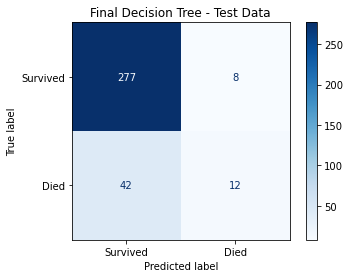

In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Survived', 'Died']
)

disp.plot(cmap='Blues')

plt.title('Final Decision Tree - Test Data')
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Survived', 'Died']
)

disp.plot(cmap='Blues')

plt.title('Final Decision Tree - Test Data')
plt.show()

In [ ]:
## Conclusion




In [33]:
# Calculate accuracy across all datasets
train_accuracy = dt_depth3.score(X_train, y_train)
validation_accuracy = dt_depth3.score(X_validate, y_validate)
test_accuracy = dt_depth3.score(X_test, y_test)

# Create comparison table
accuracy_comparison = pd.DataFrame({
    'Dataset': ['Training', 'Validation', 'Test'],
    'Accuracy': [
        train_accuracy,
        validation_accuracy,
        test_accuracy
    ]
})

print(accuracy_comparison)

      Dataset  Accuracy
0    Training  0.876969
1  Validation  0.866469
2        Test  0.852507
